# Cierres de relaciones

**Matemática Discreta (2026/27)** · Edgar Martínez-Moro · Departamento de Matemática Aplicada, Escuela de Ingeniería Informática, Universidad de Valladolid

Este cuaderno acompaña a la sesión 13 del tema de **relaciones binarias**. Contiene:

1. Operaciones con matrices booleanas.
2. Los cierres reflexivo, simétrico y transitivo, y el cierre transitivo como solución de un sistema lineal.
3. El orden en que se aplican los cierres.
4. La menor relación de equivalencia que contiene a una relación: $tsr(\mathcal R)$.
5. El retículo de las particiones: refinamiento, ínfimo, supremo y diagrama de Hasse.

El algoritmo de Warshall para el cierre transitivo se verá en el tema de grafos.

## Repaso

Si $\mathcal R$ es una relación en $A$, $|A|=n$, y $M$ es su matriz booleana:

$$r(M)=M+I,\qquad s(M)=M+M^t,\qquad t(M)=\sum_{k=1}^{n}M^k,$$

donde la suma y el producto son booleanos: $1+1=1$, y $(MN)_{ij}=1$ si hay algún $k$ con $M_{ik}=N_{kj}=1$.

La matriz $M$ se guarda como una lista de filas de ceros y unos: $M[i][j]=1$ si $(a_i,a_j)\in\mathcal R$.

## 1. Matrices booleanas

In [1]:
%matplotlib inline
from itertools import product
import random
import time


def matriz(elementos, R):
    return [[1 if (a, b) in R else 0 for b in elementos] for a in elementos]


def pares(elementos, M):
    return {(a, b) for i, a in enumerate(elementos)
            for j, b in enumerate(elementos) if M[i][j]}


def identidad(n):
    return [[1 if i == j else 0 for j in range(n)] for i in range(n)]


def traspuesta(M):
    return [list(fila) for fila in zip(*M)]


def suma_bool(M, N):
    """(M + N)_ij = M_ij OR N_ij"""
    return [[a | b for a, b in zip(f, g)] for f, g in zip(M, N)]


def producto_bool(M, N):
    """(M N)_ij = OR_k (M_ik AND N_kj)"""
    Nt = traspuesta(N)
    return [[int(any(a & b for a, b in zip(f, c))) for c in Nt] for f in M]


def contenida(M, N):
    """M <= N  (cada 1 de M es también un 1 de N)"""
    return all(a <= b for f, g in zip(M, N) for a, b in zip(f, g))

`mostrar_matrices` escribe varias matrices en paralelo y, si se le pasa `antes`, marca con `1*` los unos nuevos.

In [2]:
def fmt(conjunto):
    return "{" + ", ".join(str(x) for x in conjunto) + "}"


def fmt_particion(P):
    return "{" + ", ".join(fmt(B) for B in P) + "}"


def mostrar_matrices(elementos, *matrices, titulos=None, antes=None):
    """
    Escribe varias matrices en paralelo. Si se da `antes`, los unos que no
    estaban en `antes` se marcan con un asterisco.
    """
    elementos = list(elementos)
    n = len(elementos)
    ancho = max(len(str(x)) for x in elementos)

    def celda(M, i, j):
        if M[i][j] and antes is not None and not antes[i][j]:
            return "1*"
        return "1 " if M[i][j] else "0 "

    bloques = []
    for M in matrices:
        lineas = [" " * (ancho + 1) + " ".join(str(b).rjust(ancho) + " " for b in elementos)]
        for i, a in enumerate(elementos):
            lineas.append(str(a).rjust(ancho) + " "
                          + " ".join(celda(M, i, j).rjust(ancho + 1) for j in range(n)))
        bloques.append(lineas)
    w = len(bloques[0][0])
    if titulos:
        print("     ".join(t.ljust(w) for t in titulos).rstrip())
    for k in range(n + 1):
        print("     ".join(b[k].ljust(w) for b in bloques).rstrip())

In [3]:
A = [1, 2, 3, 4]
R = {(1, 3), (1, 4), (2, 2), (3, 3), (4, 1)}
M = matriz(A, R)
mostrar_matrices(A, M, traspuesta(M), producto_bool(M, M),
                 titulos=["M", "M^t", "M^2"])

M                 M^t               M^2
  1  2  3  4        1  2  3  4        1  2  3  4
1 0  0  1  1      1 0  0  0  1      1 1  0  1  0
2 0  1  0  0      2 0  1  0  0      2 0  1  0  0
3 0  0  1  0      3 1  0  1  0      3 0  0  1  0
4 1  0  0  0      4 1  0  0  0      4 0  0  1  1


## 2. Los cierres

In [4]:
def es_reflexiva(M):
    return all(M[i][i] for i in range(len(M)))


def es_simetrica(M):
    return M == traspuesta(M)


def es_transitiva(M):
    return contenida(producto_bool(M, M), M)        # M^2 <= M


def cierre_reflexivo(M):
    return suma_bool(M, identidad(len(M)))          # M + I


def cierre_simetrico(M):
    return suma_bool(M, traspuesta(M))              # M + M^t


def cierre_transitivo(M):
    T = P = M
    for _ in range(len(M) - 1):
        P = producto_bool(P, M)                     # P = M^k
        T = suma_bool(T, P)                         # T = M + ... + M^k
    return T

El ejemplo de clase. Los pares añadidos aparecen como `1*`:

In [5]:
r, s = cierre_reflexivo(M), cierre_simetrico(M)
t = cierre_transitivo(M)
mostrar_matrices(A, M, r, s, t, titulos=["M", "r(M)", "s(M)", "t(M)"], antes=M)
print()
print("reflexiva:", es_reflexiva(M), es_reflexiva(r))
print("simétrica:", es_simetrica(M), es_simetrica(s))
print("transitiva:", es_transitiva(M), es_transitiva(t))

M                 r(M)              s(M)              t(M)
  1  2  3  4        1  2  3  4        1  2  3  4        1  2  3  4
1 0  0  1  1      1 1* 0  1  1      1 0  0  1  1      1 1* 0  1  1
2 0  1  0  0      2 0  1  0  0      2 0  1  0  0      2 0  1  0  0
3 0  0  1  0      3 0  0  1  0      3 1* 0  1  0      3 0  0  1  0
4 1  0  0  0      4 1  0  0  1*     4 1  0  0  0      4 1  0  1* 1*

reflexiva: False True
simétrica: False True
transitiva: False True


`mostrar_cierre_transitivo` va sumando las potencias $M^k$ y dice qué pares aporta cada una. En el ejemplo todo sale con $k=2$:

In [6]:
def mostrar_cierre_transitivo(elementos, M):
    """Las potencias M^k, una a una, con los pares nuevos que aportan."""
    elementos = list(elementos)
    T = P = M
    print(f"  k=1: M     da {len(pares(elementos, M))} pares")
    for k in range(2, len(M) + 1):
        P = producto_bool(P, M)
        nuevo = suma_bool(T, P)
        aporta = sorted(pares(elementos, nuevo) - pares(elementos, T))
        texto = ", ".join(f"({a},{b})" for a, b in aporta) if aporta else "nada nuevo"
        print(f"  k={k}: M^{k}   añade {texto}")
        T = nuevo
    return T

In [7]:
mostrar_cierre_transitivo(A, M);

  k=1: M     da 5 pares
  k=2: M^2   añade (1,1), (4,3), (4,4)
  k=3: M^3   añade nada nuevo
  k=4: M^4   añade nada nuevo


Con una cadena $1\to2\to3\to4$ hacen falta caminos más largos: $M^2$ aporta los caminos de longitud $2$ y $M^3$ el de longitud $3$.

In [8]:
C = matriz(A, {(1, 2), (2, 3), (3, 4)})
T = mostrar_cierre_transitivo(A, C)
mostrar_matrices(A, C, T, titulos=["M", "t(M)"], antes=C)

  k=1: M     da 3 pares
  k=2: M^2   añade (1,3), (2,4)
  k=3: M^3   añade (1,4)
  k=4: M^4   añade nada nuevo
M                 t(M)
  1  2  3  4        1  2  3  4
1 0  1  0  0      1 0  1  1* 1*
2 0  0  1  0      2 0  0  1  1*
3 0  0  0  1      3 0  0  0  1
4 0  0  0  0      4 0  0  0  0


**Coste.** Cada producto booleano de matrices $n\times n$ hace del orden de $n^3$ operaciones y el cierre transitivo hace $n-1$ productos: del orden de $n^4$. Un poco más abajo vemos cómo bajarlo resolviendo un sistema lineal.

In [9]:
import random
random.seed(1)
for n in (10, 20, 40, 80):
    Mn = [[int(random.random() < 1.5 / n) for _ in range(n)] for _ in range(n)]
    t0 = time.perf_counter(); cierre_transitivo(Mn); t1 = time.perf_counter()
    print(f"n = {n:>3}: {t1 - t0:7.3f} s")

n =  10:   0.001 s
n =  20:   0.007 s
n =  40:   0.130 s


n =  80:   1.379 s


### El cierre transitivo con un sistema lineal

En el álgebra booleana no se puede restar, así que pasamos a los **enteros**: allí $(M^k)_{ij}$ es el número de caminos de longitud $k$ de $a_i$ a $a_j$, y $t(M)$ son las entradas no nulas de $M+M^2+\dots+M^n$ (todos los sumandos son $\ge 0$, así que no se cancela nada).

Para cualquier matriz cuadrada,

$$(M-I)\,(I+M+\dots+M^k)=M^{k+1}-I,$$

así que, si $M-I$ es invertible, $X=I+M+\dots+M^k$ es la única solución del sistema $(M-I)X=M^{k+1}-I$. En vez de sumar $n$ potencias, basta calcular $M^{k+1}$ (por cuadrados sucesivos, unos $2\log_2 k$ productos) y resolver un sistema (Gauss, unas $n^3$ operaciones): del orden de $n^3\log n$ frente a $n^4$.

Para no confundir una entrada pequeña con un cero, el sistema se resuelve de forma **exacta**, con fracciones.

In [10]:
from fractions import Fraction


def producto(M, N):
    """Producto de matrices de enteros (no booleano)."""
    Nt = list(zip(*N))
    return [[sum(a * b for a, b in zip(f, c)) for c in Nt] for f in M]


def potencia(M, k):
    """M^k por cuadrados sucesivos: unos 2 log2(k) productos."""
    R, P = identidad(len(M)), M
    while k:
        if k % 2 == 1:
            R = producto(R, P)
        P, k = producto(P, P), k // 2
    return R


def resolver(A, B):
    """Solución exacta (en Q) de A X = B, con A invertible (Gauss-Jordan)."""
    n = len(A)
    F = [[Fraction(x) for x in A[i] + B[i]] for i in range(n)]
    for c in range(n):
        p = next(i for i in range(c, n) if F[i][c] != 0)    # pivote
        F[c], F[p] = F[p], F[c]
        piv = F[c][c]
        F[c] = [x / piv for x in F[c]]
        for i in range(n):
            if i != c and F[i][c] != 0:
                f = F[i][c]
                F[i] = [x - f * y for x, y in zip(F[i], F[c])]
    return [fila[n:] for fila in F]


def suma_geometrica(M, k):
    """X = I + M + ... + M^k, como solución de (M - I) X = M^(k+1) - I."""
    n = len(M)
    A = [[M[i][j] - (i == j) for j in range(n)] for i in range(n)]
    P = potencia(M, k + 1)
    B = [[P[i][j] - (i == j) for j in range(n)] for i in range(n)]
    return resolver(A, B)

Comprobamos la fórmula con la cadena $1\to2\to3\to4$, donde $M-I$ es invertible:

In [11]:
X = suma_geometrica(C, 3)
print([[int(x) for x in fila] for fila in X])
S = identidad(4)
for k in range(1, 4):
    S = suma_bool(S, potencia(C, k))
print(S)

[[1, 1, 1, 1], [0, 1, 1, 1], [0, 0, 1, 1], [0, 0, 0, 1]]
[[1, 1, 1, 1], [0, 1, 1, 1], [0, 0, 1, 1], [0, 0, 0, 1]]


**Problema.** En el ejemplo de clase $(2,2),(3,3)\in\mathcal R$, y $M-I$ tiene dos filas nulas: no es invertible. Esto ocurre exactamente cuando $1$ es valor propio de $M$.

In [12]:
for fila in [[M[i][j] - (i == j) for j in range(4)] for i in range(4)]:
    print(fila)
try:
    suma_geometrica(M, 4)
except StopIteration:
    print("no hay pivote: M - I no es invertible")

[-1, 0, 1, 1]
[0, 0, 0, 0]
[0, 0, 0, 0]
[1, 0, 0, -1]
no hay pivote: M - I no es invertible


**Arreglo.** Usamos $2M$: sus potencias $(2M)^k=2^kM^k$ tienen las mismas entradas no nulas que las de $M$, y

> si $M$ es una matriz de enteros, $2M-I$ es invertible.

En efecto, si $(2M-I)v=0$ con $v\neq0$, $\frac12$ sería valor propio de $M$, es decir, raíz racional de su polinomio característico, que es mónico con coeficientes enteros. Y las raíces racionales de un polinomio así son enteras.

In [13]:
def cierre_transitivo_sistema(M):
    """t(M): entradas no nulas de X - I, con X = I + 2M + ... + (2M)^n."""
    n = len(M)
    D = [[2 * x for x in fila] for fila in M]                 # 2M
    X = suma_geometrica(D, n)
    return [[int(X[i][j] - (i == j) != 0) for j in range(n)]
            for i in range(n)]

In [14]:
X = suma_geometrica([[2 * x for x in f] for f in M], 4)   # I + 2M + ... + (2M)^4
for fila in X:
    print([int(x) for x in fila])
mostrar_matrices(A, M, cierre_transitivo_sistema(M), titulos=["M", "t(M)"], antes=M)

[21, 0, 54, 10]
[0, 31, 0, 0]
[0, 0, 31, 0]
[10, 0, 44, 21]
M                 t(M)
  1  2  3  4        1  2  3  4
1 0  0  1  1      1 1* 0  1  1
2 0  1  0  0      2 0  1  0  0
3 0  0  1  0      3 0  0  1  0
4 1  0  0  0      4 1  0  1* 1*


$X_{22}=1+2+4+8+16=31$: el bucle en $2$ da un camino de cada longitud. Quitando la diagonal de $I$, las entradas no nulas de $X$ son las de $t(M)$.

### Llevando $k$ a infinito

Con $N=\frac1{n+1}M$ cada fila de $N$ suma menos que $1$, así que $N^{k+1}\to0$. En el límite el sistema $(N-I)X=N^{k+1}-I$ queda $(I-N)X=I$ y, multiplicando por $n+1$,

$$\big((n+1)I-M\big)\,Y=I,\qquad Y=\tfrac1{n+1}\sum_{k\ge0}N^k.$$

La matriz $(n+1)I-M$ siempre es invertible (es de diagonal estrictamente dominante) y $MY=(n+1)Y-I=\sum_{k\ge1}N^k$ tiene las mismas entradas no nulas que $t(M)$. Ya no hace falta calcular potencias.

In [15]:
def cierre_transitivo_limite(M):
    """
    Con k -> infinito y M/(n+1) en lugar de M: ((n+1) I - M) Y = I.
    Entonces M Y = (n+1) Y - I tiene las mismas entradas no nulas que t(M).
    """
    n = len(M)
    A = [[(n + 1) * (i == j) - M[i][j] for j in range(n)]
         for i in range(n)]                                    # (n+1) I - M
    Y = resolver(A, identidad(n))
    Z = [[(n + 1) * Y[i][j] - (i == j) for j in range(n)]
         for i in range(n)]                                    # Z = M Y
    return [[int(z != 0) for z in fila] for fila in Z]

In [16]:
n = 4
Y = resolver([[(n + 1) * (i == j) - M[i][j] for j in range(n)] for i in range(n)], identidad(n))
for i in range(n):
    print([str((n + 1) * Y[i][j] - (i == j)) for j in range(n)])
print(cierre_transitivo_limite(M) == cierre_transitivo(M))

['1/24', '0', '25/96', '5/24']
['0', '1/4', '0', '0']
['0', '0', '1/4', '0']
['5/24', '0', '5/96', '1/24']
True


Los tres métodos coinciden en las $2^{16}=65536$ relaciones en $\{1,2,3,4\}$. `todas_las_matrices(n)` genera las $2^{n^2}$ matrices booleanas $n\times n$:

In [17]:
def todas_las_matrices(n):
    """Las 2^(n^2) matrices booleanas n x n."""
    for bits in product((0, 1), repeat=n * n):
        yield [list(bits[i * n:(i + 1) * n]) for i in range(n)]

In [18]:
t0 = time.perf_counter()
print(all(cierre_transitivo(Q) == cierre_transitivo_sistema(Q) == cierre_transitivo_limite(Q)
          for Q in todas_las_matrices(4)), f"({time.perf_counter() - t0:.1f} s)")

True (26.5 s)


### Comparación de tiempos

Con relaciones dispersas (una media de $1{,}5$ pares por elemento), los sistemas ganan claramente:

In [19]:
def comparar(n, densidad, semilla=2026):
    random.seed(semilla)
    Q = [[int(random.random() < densidad) for _ in range(n)] for _ in range(n)]
    t0 = time.perf_counter(); T1 = cierre_transitivo(Q)
    t1 = time.perf_counter(); T2 = cierre_transitivo_sistema(Q)
    t2 = time.perf_counter(); T3 = cierre_transitivo_limite(Q)
    t3 = time.perf_counter()
    assert T1 == T2 == T3
    print(f"n = {n:>3}: potencias {t1 - t0:6.2f} s | sistema {t2 - t1:5.2f} s"
          f" | límite {t3 - t2:5.2f} s")

for n in (20, 40, 80, 160):
    comparar(n, 1.5 / n)

n =  20: potencias   0.01 s | sistema  0.01 s | límite  0.00 s


n =  40: potencias   0.11 s | sistema  0.05 s | límite  0.03 s


n =  80: potencias   1.67 s | sistema  0.28 s | límite  0.07 s


n = 160: potencias  23.49 s | sistema  3.42 s | límite  1.20 s


Con relaciones densas, en cambio, las fracciones del método de Gauss se hacen enormes (cientos de cifras) y cada operación es cara, mientras que el producto booleano con `any` se detiene en cuanto encuentra un $1$. Entonces el método de las potencias vuelve a ganar:

In [20]:
for n in (40, 80):
    comparar(n, 0.5)

n =  40: potencias   0.04 s | sistema  0.29 s | límite  0.33 s


n =  80: potencias   0.23 s | sistema  3.50 s | límite  4.37 s


Contar operaciones no basta: también importa lo que cuesta cada una. En el tema de grafos veremos el algoritmo de Warshall, que trabaja con ceros y unos y hace unas $n^3$ operaciones booleanas.

### Propiedades que se conservan

En clase vimos que el cierre simétrico de una relación transitiva puede no ser transitivo. Lo comprobamos para todas las relaciones en $\{1,2,3\}$, junto con el resto de la proposición:

In [21]:
M3 = list(todas_las_matrices(3))
print(len(M3), "relaciones en {1, 2, 3}")
casos = [
    ("R reflexiva  => s(R) reflexiva", es_reflexiva, cierre_simetrico, es_reflexiva),
    ("R reflexiva  => t(R) reflexiva", es_reflexiva, cierre_transitivo, es_reflexiva),
    ("R simétrica  => r(R) simétrica", es_simetrica, cierre_reflexivo, es_simetrica),
    ("R simétrica  => t(R) simétrica", es_simetrica, cierre_transitivo, es_simetrica),
    ("R transitiva => r(R) transitiva", es_transitiva, cierre_reflexivo, es_transitiva),
    ("R transitiva => s(R) transitiva", es_transitiva, cierre_simetrico, es_transitiva),
]
for texto, hip, cierre, tesis in casos:
    fallos = [X for X in M3 if hip(X) and not tesis(cierre(X))]
    print(f"{texto}: {'sí' if not fallos else f'NO, falla en {len(fallos)} casos'}")

512 relaciones en {1, 2, 3}
R reflexiva  => s(R) reflexiva: sí
R reflexiva  => t(R) reflexiva: sí
R simétrica  => r(R) simétrica: sí
R simétrica  => t(R) simétrica: sí
R transitiva => r(R) transitiva: sí
R transitiva => s(R) transitiva: NO, falla en 132 casos


## 3. ¿Importa el orden de los cierres?

`componer("st", M)` calcula $s(t(M))$: las letras se aplican de derecha a izquierda, como en la notación de clase.

In [22]:
CIERRES = {"r": cierre_reflexivo, "s": cierre_simetrico, "t": cierre_transitivo}


def componer(palabra, M):
    """componer("tsr", M) = t(s(r(M))): se aplica de derecha a izquierda."""
    for letra in reversed(palabra):
        M = CIERRES[letra](M)
    return M


def es_equivalencia(M):
    return es_reflexiva(M) and es_simetrica(M) and es_transitiva(M)

In [23]:
for a, b in [("r", "s"), ("r", "t"), ("s", "t")]:
    distintas = sum(componer(a + b, X) != componer(b + a, X) for X in M3)
    print(f"{a}{b} != {b}{a} en {distintas} de {len(M3)}")
print("st contenida en ts siempre:",
      all(contenida(componer("st", X), componer("ts", X)) for X in M3))

rs != sr en 0 de 512
rt != tr en 0 de 512
st != ts en 240 de 512
st contenida en ts siempre: True


El contraejemplo más pequeño de $st\neq ts$ (el que tiene menos pares):

In [24]:
E3 = [1, 2, 3]
malos = [X for X in M3 if componer("st", X) != componer("ts", X)]
X = min(malos, key=lambda X: sum(map(sum, X)))
print("R =", sorted(pares(E3, X)))
mostrar_matrices(E3, X, componer("st", X), componer("ts", X),
                 titulos=["R", "st(R)", "ts(R)"], antes=X)

R = [(3, 2)]
R              st(R)          ts(R)
  1  2  3        1  2  3        1  2  3
1 0  0  0      1 0  0  0      1 0  0  0
2 0  0  0      2 0  0  1*     2 0  1* 1*
3 0  1  0      3 0  1  0      3 0  1  1*


$\mathcal R=\{(3,2)\}$ es transitiva, así que $t(\mathcal R)=\mathcal R$ y $st(\mathcal R)=\{(2,3),(3,2)\}$, que no es transitiva. En cambio $ts(\mathcal R)$ añade además $(2,2)$ y $(3,3)$.

¿Con qué órdenes de los tres cierres se obtiene siempre una relación de equivalencia?

In [25]:
for w in ["rst", "srt", "str", "rts", "trs", "tsr"]:
    print(w, sum(es_equivalencia(componer(w, X)) for X in M3), "de", len(M3))
print("tsr = rts = trs siempre:",
      all(componer("tsr", X) == componer("rts", X) == componer("trs", X) for X in M3))

rst 464 de 512
srt 464 de 512
str 464 de 512
rts 512 de 512
trs 512 de 512
tsr 512 de 512


tsr = rts = trs siempre: True


Las tres palabras que fallan aplican $s$ **después** de $t$. Basta con hacer $t$ después de $s$; el cierre reflexivo puede ir en cualquier sitio.

## 4. La menor relación de equivalencia que contiene a $\mathcal R$

In [26]:
def cierre_equivalencia(M):
    """tsr(R): la menor relación de equivalencia que contiene a R."""
    return cierre_transitivo(cierre_simetrico(cierre_reflexivo(M)))


def clases(elementos, M):
    """Clases de una relación de equivalencia dada por su matriz."""
    elementos = list(elementos)
    resultado, vistos = [], set()
    for j, x in enumerate(elementos):
        if x not in vistos:
            c = [elementos[i] for i in range(len(elementos)) if M[i][j]]
            resultado.append(c)
            vistos.update(c)
    return resultado


def clases_union_find(elementos, lista_pares):
    padre = {x: x for x in elementos}

    def raiz(x):
        while padre[x] != x:
            padre[x] = padre[padre[x]]
            x = padre[x]
        return x

    for a, b in lista_pares:
        ra, rb = raiz(a), raiz(b)
        if ra != rb:
            padre[rb] = ra
    c = {}
    for x in elementos:
        c.setdefault(raiz(x), []).append(x)
    return list(c.values())

In [27]:
Eq = cierre_equivalencia(M)
mostrar_matrices(A, M, Eq, titulos=["M", "tsr(M)"], antes=M)
print("A / tsr(R)      :", clases(A, Eq))
print("unión-búsqueda  :", clases_union_find(A, sorted(R)))

M                 tsr(M)
  1  2  3  4        1  2  3  4
1 0  0  1  1      1 1* 0  1  1
2 0  1  0  0      2 0  1  0  0
3 0  0  1  0      3 1* 0  1  1*
4 1  0  0  0      4 1  0  1* 1*
A / tsr(R)      : [[1, 3, 4], [2]]
unión-búsqueda  : [[1, 3, 4], [2]]


La unión-búsqueda de la sesión 12 da directamente $A/tsr(\mathcal R)$, sin matrices: recorre los pares de $\mathcal R$ una sola vez. Lo comprobamos con todas las relaciones en $\{1,2,3,4\}$ ($2^{16}=65536$):

In [28]:
def normal(c):
    return sorted(sorted(B) for B in c)

t0 = time.perf_counter()
ok = all(normal(clases(A, cierre_equivalencia(X))) == normal(clases_union_find(A, pares(A, X)))
         for X in todas_las_matrices(4))
print(ok, f"({time.perf_counter() - t0:.1f} s)")

True (3.0 s)


## 5. El retículo de las particiones $(\Pi(A),\le)$

$P_1\le P_2$ ($P_1$ **refina** a $P_2$) si cada bloque de $P_1$ está dentro de algún bloque de $P_2$. Es un retículo:

- $\inf\{P_1,P_2\}$: las intersecciones no vacías de un bloque de $P_1$ con uno de $P_2$, es decir, $A/(\mathcal R_1\cap\mathcal R_2)$.
- $\sup\{P_1,P_2\}$: se juntan los bloques que se solapan, es decir, $A/t(\mathcal R_1\cup\mathcal R_2)$. Lo calculamos con unión-búsqueda: cada bloque se describe con los pares que unen su primer elemento con los demás.

`corto` escribe una partición de forma compacta: `12|3|4` es $\{\{1,2\},\{3\},\{4\}\}$.

In [29]:
def particiones(elementos):
    """Genera todas las particiones de `elementos` (listas de bloques)."""
    elementos = list(elementos)
    if not elementos:
        yield []
        return
    primero, resto = elementos[0], elementos[1:]
    for P in particiones(resto):
        yield [[primero]] + P
        for i in range(len(P)):
            yield P[:i] + [[primero] + P[i]] + P[i + 1:]


def normalizar(P):
    """Bloques ordenados, para comparar particiones."""
    return sorted(sorted(B) for B in P)


def refina(P1, P2):
    """P1 <= P2: cada bloque de P1 está dentro de algún bloque de P2."""
    return all(any(set(B1) <= set(B2) for B2 in P2) for B1 in P1)


def inf_particiones(P1, P2):
    """Intersecciones no vacías de un bloque de P1 con uno de P2."""
    return normalizar(set(B1) & set(B2) for B1 in P1 for B2 in P2
                      if set(B1) & set(B2))


def sup_particiones(P1, P2):
    """Junta los bloques que se solapan (unión-búsqueda)."""
    elementos = [x for B in P1 for x in B]
    enlaces = [(B[0], x) for B in P1 + P2 for x in B[1:]]
    return normalizar(clases_union_find(elementos, enlaces))


def corto(P):
    """Notación compacta: {{1,2},{3},{4}} -> 12|3|4"""
    sep = "" if all(len(str(x)) == 1 for B in P for x in B) else ","
    return "|".join(sep.join(str(x) for x in B) for B in sorted(normalizar(P), key=lambda B: (-len(B), B)))

In [30]:
P1, P2 = [[1, 2], [3], [4]], [[2, 3], [1], [4]]
print("P1 <= P2:", refina(P1, P2), "   P2 <= P1:", refina(P2, P1))
print("inf:", corto(inf_particiones(P1, P2)))
print("sup:", corto(sup_particiones(P1, P2)))
print(refina([[1], [2], [3, 4]], [[1, 2], [3, 4]]))

P1 <= P2: False    P2 <= P1: False
inf: 1|2|3|4
sup: 123|4
True


El supremo coincide con $A/t(\mathcal R_1\cup\mathcal R_2)$, calculado con matrices:

In [31]:
def rel(P):                                # relación asociada a una partición
    return {(x, y) for B in P for x in B for y in B}

M12 = suma_bool(matriz(A, rel(P1)), matriz(A, rel(P2)))
print(normalizar(clases(A, cierre_transitivo(M12))))

[[1, 2, 3], [4]]


Comprobamos que el ínfimo y el supremo calculados son de verdad la mayor cota inferior y la menor cota superior, para los $15^2=225$ pares de particiones de $\{1,2,3,4\}$; y que el supremo es siempre $A/t(\mathcal R_1\cup\mathcal R_2)$:

In [32]:
L = [normalizar(P) for P in particiones(A)]
print(len(L), "particiones;  por número de bloques:",
      [sum(len(P) == k for P in L) for k in range(1, 5)])
ok = True
for P in L:
    for Q in L:
        i, s = inf_particiones(P, Q), sup_particiones(P, Q)
        inf_ = [X for X in L if refina(X, P) and refina(X, Q)]
        sup_ = [X for X in L if refina(P, X) and refina(Q, X)]
        ok = ok and i in inf_ and all(refina(X, i) for X in inf_)
        ok = ok and s in sup_ and all(refina(s, X) for X in sup_)
        MPQ = suma_bool(matriz(A, rel(P)), matriz(A, rel(Q)))
        ok = ok and normalizar(clases(A, cierre_transitivo(MPQ))) == s
print("es un retículo con esas operaciones:", ok)

15 particiones;  por número de bloques: [1, 7, 6, 1]
es un retículo con esas operaciones: True


### El diagrama de Hasse

$P_2$ cubre a $P_1$ si se obtiene juntando dos bloques de $P_1$. Una partición con $k$ bloques está cubierta por $\binom k2$ particiones.

In [33]:
def aristas_hasse_particiones(lista):
    """P2 cubre a P1 si P2 se obtiene juntando dos bloques de P1."""
    return [(i, j) for i, P1 in enumerate(lista) for j, P2 in enumerate(lista)
            if len(P2) == len(P1) - 1 and refina(P1, P2)]


def dibujar_particiones(elementos, archivo=None, titulo=None):
    """Diagrama de Hasse de (Pi(A), <=) con matplotlib."""
    import matplotlib.pyplot as plt

    elementos = list(elementos)
    n = len(elementos)
    lista = [normalizar(P) for P in particiones(elementos)]
    aristas = aristas_hasse_particiones(lista)
    niveles = [[i for i, P in enumerate(lista) if len(P) == n - y] for y in range(n)]
    vecinos = {i: [] for i in range(len(lista))}
    for a, b in aristas:
        vecinos[a].append(b)
        vecinos[b].append(a)
    def recolocar(nivel, ref):                       # baricentro: menos cruces
        lugar = {x: i for i, x in enumerate(ref)}
        antes = {x: i for i, x in enumerate(nivel)}
        def media(x):
            v = [lugar[y] for y in vecinos[x] if y in lugar]
            return sum(v) / len(v) if v else antes[x]
        nivel.sort(key=media)
    for _ in range(4):
        for k in range(1, n):
            recolocar(niveles[k], niveles[k - 1])
        for k in range(n - 2, -1, -1):
            recolocar(niveles[k], niveles[k + 1])
    sep = 0.25 * n + 0.6
    pos = {}
    for y, nivel in enumerate(niveles):
        for i, x in enumerate(nivel):
            pos[x] = (sep * (i - (len(nivel) - 1) / 2), y)
    fig, ax = plt.subplots(figsize=(max(4, 1.1 * sep * max(map(len, niveles))), 1.3 * n + 0.6))
    for a, b in aristas:
        (x1, y1), (x2, y2) = pos[a], pos[b]
        ax.plot([x1, x2], [y1, y2], color="teal", lw=1, zorder=1)
    for i, (px, py) in pos.items():
        ax.text(px, py, corto(lista[i]), ha="center", va="center", fontsize=9, zorder=3,
                bbox=dict(boxstyle="round,pad=0.3", fc="#e6f2f2", ec="teal", lw=1))
    ax.set_title(titulo or f"Particiones de {fmt(elementos)}", fontsize=10)
    ax.set_axis_off()
    ax.margins(0.08)
    fig.tight_layout()
    if archivo:
        fig.savefig(archivo, dpi=150)
        plt.close(fig)
    else:
        plt.show()
    return fig

31 aristas


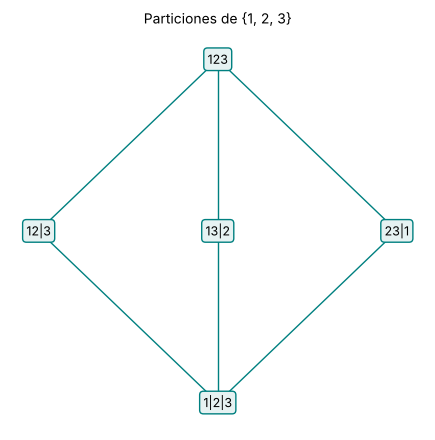

In [34]:
print(len(aristas_hasse_particiones(L)), "aristas")
dibujar_particiones([1, 2, 3]);

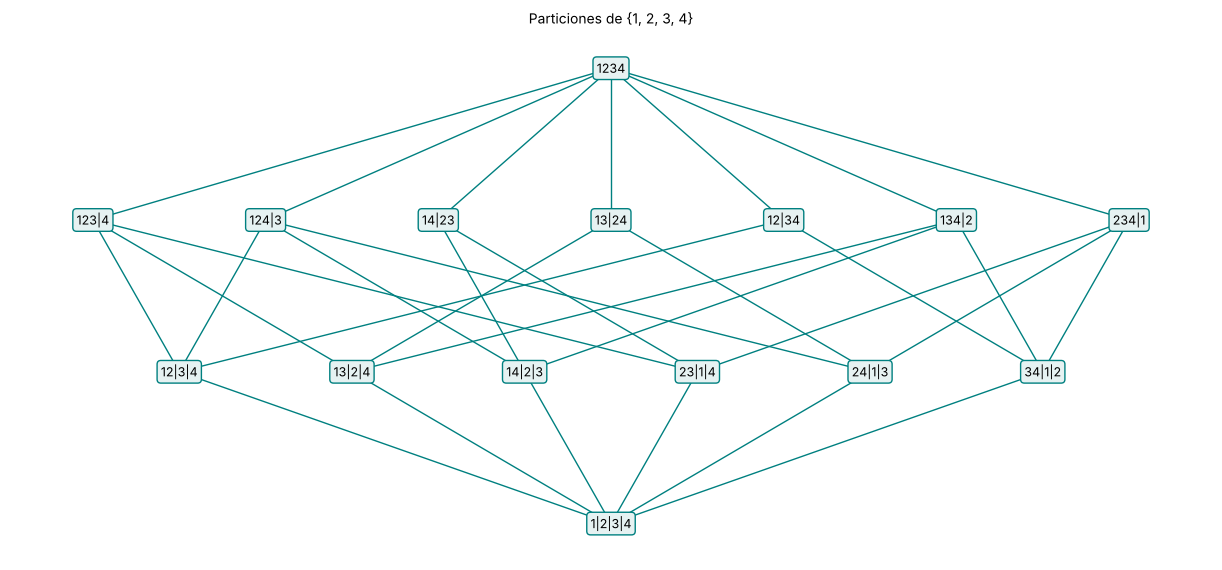

In [35]:
dibujar_particiones([1, 2, 3, 4]);

Por niveles aparecen los números de Stirling: en $\Pi(\{1,2,3,4\})$ hay $1, 6, 7, 1$ particiones con $4, 3, 2, 1$ bloques, y $1\cdot6+6\cdot3+7\cdot1=31$ aristas.

## Referencias

- Grimaldi, R. P. (1998). *Matemática discreta y combinatoria* (3ª ed.). Addison Wesley Longman.
- Rosen, K. H. (2004). *Matemática discreta y sus aplicaciones* (5ª ed.). McGraw-Hill.